<a href="https://colab.research.google.com/github/SEOWOOJI/2026_FallSemester_AI_Course/blob/main/mnist_classifier_%EB%AA%A8%EB%8D%B8%EA%B0%9C%EC%84%A0_2024231%EC%A7%80%EC%84%9C%EC%9A%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, TensorDataset
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import seaborn as sns

In [2]:
# 시드 고정 (재현 가능한 결과를 위해)
torch.manual_seed(42)
np.random.seed(42)

## 1. 데이터 불러오기

In [3]:
# 1️. 데이터 변환 설정: 우선 ToTensor()만 적용한 버전으로 불러오기
# : 파이토치가 처리하기 좋게 데이터 변환
transform = transforms.Compose([
    transforms.ToTensor()
])

# MNIST 데이터셋 불러오기
train_dataset = torchvision.datasets.MNIST(root='./data', train=True,
                                          transform=transform, download=True)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False,
                                         transform=transform, download=True)

print("\n"+"train dataset :", len(train_dataset))
print("test dataset :", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 60.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.83MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.0MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.71MB/s]


train dataset : 60000
test dataset : 10000


In [4]:
# 하나의 샘플 확인
img, label = next(iter(train_dataset))
print(img.shape, label)

torch.Size([1, 28, 28]) 5


##2. 데이터셋 전처리

In [21]:
# 2. 평균, 표준편차 계산
# 모든 데이터를 하나로 모아 계산[1, 28, 28]
all_data = torch.cat([img.view(1, -1) for img, _ in train_dataset], dim=0)
mean = all_data.mean()
std = all_data.std()

print('Global Mean:', mean)
print('Global Std:', std)

# 3️. 실제 학습용 변환 정의 (계산한 mean/std 사용)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean.tolist(), std.tolist())
])

# 4️. MNIST 데이터셋 불러오기 (정규화 적용)
train_dataset = torchvision.datasets.MNIST(root='./data', train=True,
                                          transform=transform, download=True)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False,
                                         transform=transform, download=True)

Global Mean: tensor(0.1307)
Global Std: tensor(0.3081)


In [6]:
print(train_dataset)
print(test_dataset)

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=0.13066047430038452, std=0.30810782313346863)
           )
Dataset MNIST
    Number of datapoints: 10000
    Root location: ./data
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=0.13066047430038452, std=0.30810782313346863)
           )


In [22]:
# 배치 처리 및 데이터 로더 사용
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=10000, shuffle=False)

## 3. 모델 구현

In [23]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28*28, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(-1, 28*28)
        x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.bn2(self.fc2(x)))
        x = self.fc3(x)
        return x

In [15]:
# 하이퍼파라미터 설정 및 실험
model = MLP()
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# ReduceLROnPlateau: 검증 손실이 개선되지 않으면 학습률 감소
scheduler = ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.1)

In [29]:
for epoch in range(10):
    model.train()
    train_loss = 0.0
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()


    print(f'Epoch {epoch+1}, Loss: {train_loss/len(train_loader):.4f}')

Epoch 1, Loss: 0.0171
Epoch 2, Loss: 0.0164
Epoch 3, Loss: 0.0131
Epoch 4, Loss: 0.0130
Epoch 5, Loss: 0.0122
Epoch 6, Loss: 0.0136
Epoch 7, Loss: 0.0118
Epoch 8, Loss: 0.0136
Epoch 9, Loss: 0.0108
Epoch 10, Loss: 0.0137


##4. 모델 성능 평가

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

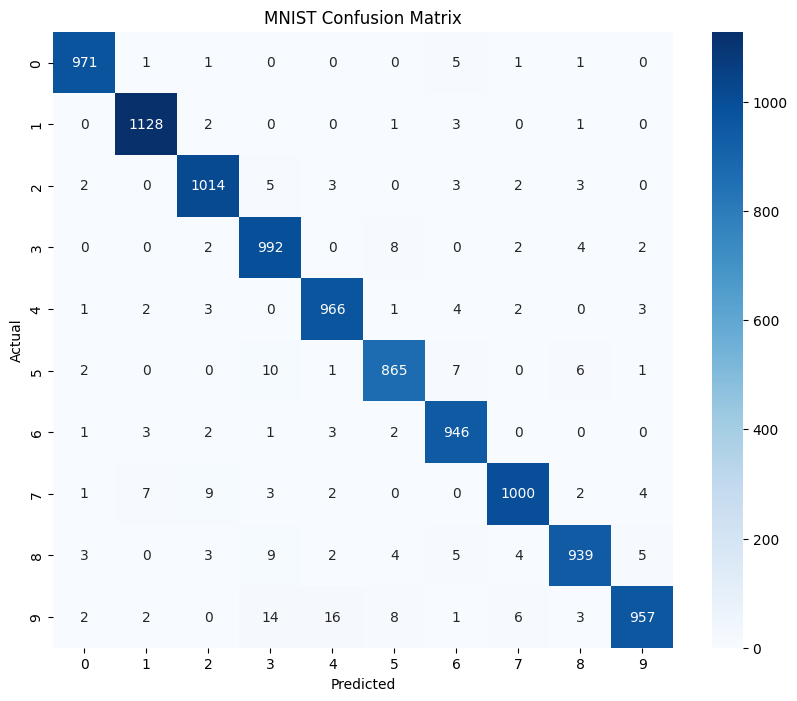

In [31]:
# 2. 실제 MNIST 결과로 혼동 행렬 생성
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

model.eval() # Set the model to evaluation mode
all_targets = []
all_preds = []
all_probs = []

# 테스트 데이터 평가: 그래디언트 끄고, 배치마다 예측 수
with torch.no_grad(): # Disable gradient calculation during evaluation
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        output = model(data)
        probs = F.softmax(output, dim=1)
        _, predicted = torch.max(output.data, 1)
        all_targets.extend(target.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

# 혼동 행렬 계
targets = np.array(all_targets)
preds = np.array(all_preds)
y_score = np.concatenate(all_probs)

# 실제 MNIST 결과로 혼동 행렬 생성
cm_mnist = confusion_matrix(targets, preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_mnist, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('MNIST Confusion Matrix')
plt.show()

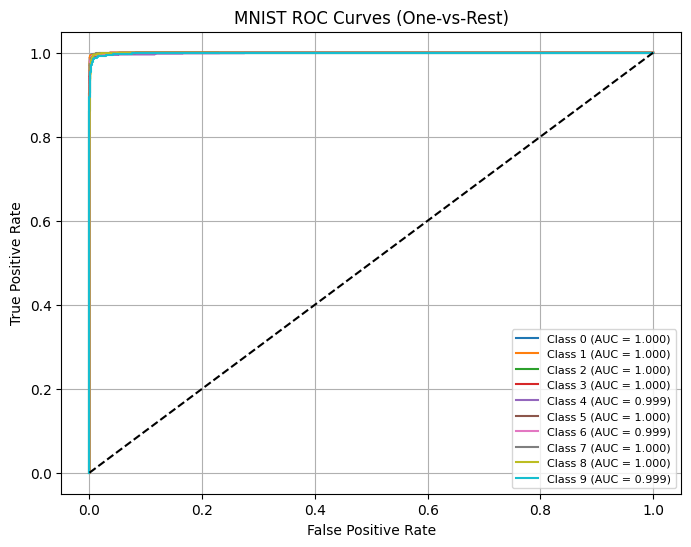

Macro AUC: 0.9995897514721029


In [32]:
# ROC 커브
y_bin = label_binarize(targets, classes=list(range(10)))   # (10000, 10)

plt.figure(figsize=(8, 6))
for i in range(10):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f'Class {i} (AUC = {auc(fpr, tpr):.3f})')

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('MNIST ROC Curves (One-vs-Rest)')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

print('Macro AUC:', roc_auc_score(y_bin, y_score, average='macro'))